# CS-6600 Project Part 1 - Exploratory Data Analysis

*Weber State University*

**Your Team**: YOUR TEAM NAME AND NAMES OF TEAM MEMBERS HERE : Jeffery Hatch, Fred Walter, Issac Christensen, Zachary Saylors

Your analysis should be below. Unlike previous assignments, there's not a lot of scaffolding provided for you. It's mostly up to you.

## Three questions
1. Can we identify the authoring LLM when evaluating responses to prompts not included in the training.
2. How do paragraph length and punctuation use differ between authoring models?
3. Are longer paragraphs easier to classify correctly than shorter paragraphs?

In [61]:
# Load tools for tables, graphs, and text measurements. Download the language resources NLTK uses to identify sentence boundaries.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
import string
import unicodedata

nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.tokenize import sent_tokenize

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Fred\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Fred\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [62]:
# Load the team's copy of the labeled dataset. Each row contains a paragraph, its prompt identifier, and its authoring model.
url = "https://raw.githubusercontent.com/FredWltr/NameThatLLM/refs/heads/main/dataset/data.csv"

data = pd.read_csv(url)
data.head()

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [63]:
# Inspect the dataset's size, columns, and an example paragraph to understand what one observation represents.

print("Number of rows:", len(data))

print("Columns:", data.columns.tolist())

display(data.head())

print("\nFirst paragraph:")
print(data.loc[0, "text"])

print("\nModel that wrote it:")
print(data.loc[0, "model"])

Number of rows: 2699
Columns: ['id', 'prompt_id', 'text', 'model']


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash



First paragraph:
When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, binding the Milky Way to ancestors, rivers, or the migration paths of birds; others encode lunar phases as verbs, so time is not a line but a recurring breath. A word can carry the exact color of dawn on snow, the etiquette of speaking to thunder, or the mathematics woven into knot calendars and oral star charts. With extinction, those relations collapse into silence. No dictionary can resurrect the sky those speakers inhabited, nor the quiet ethics it taught. We lose metaphors that made the universe intimate, ethical, and alive, cosmologies in which darkness is a listener, comets are warnings carried by relatives, and constellations are not fixed pictures but seasonal responsibilities. The loss is not merely lexical; it is the erasure of possible human answers to wonder. What rema

In [64]:
# Check missing values, exact duplicate paragraphs, and examples per model before deciding whether cleaning or class balancing is needed.
print("Missing values in each column:")
display(data.isna().sum().to_frame("missing_count"))

print("\nNumber of different prompts:")
print(data["prompt_id"].nunique())

print("\nNumber of different LLMs:")
print(data["model"].nunique())

print("\nParagraphs written by each LLM:")
display(data["model"].value_counts().to_frame("paragraph_count"))

print("\nNumber of repeated identical paragraphs:")
print(data["text"].duplicated().sum())

Missing values in each column:


,missing_count
id,0
prompt_id,0
text,0
model,0



Number of different prompts:
150

Number of different LLMs:
18

Paragraphs written by each LLM:


,paragraph_count
model,
qwen3.8-max,150
claude-sonnet-5,150
gemini-3.6-flash,150
gpt-5.6-terra,150
glm-5.3-flash,150
gemini-3.1-pro-preview,150
gemini-3.8-flash,150
claude-opus-4-6,150
gpt-5.6-luna,150



Number of repeated identical paragraphs:
0


,min,median,mean,max
model,,,,
claude-fable-5,39,100.0,112.5,252
claude-opus-4-6,42,98.5,115.1,274
claude-opus-4-8,42,109.0,123.6,251
claude-opus-5,39,116.5,123.4,257
claude-sonnet-5,39,99.5,120.0,267
gemini-3.1-pro-preview,38,104.0,119.3,262
gemini-3.6-flash,40,95.5,111.2,238
gemini-3.7-flash,40,101.5,117.1,252
gemini-3.8-flash,41,84.0,100.7,238


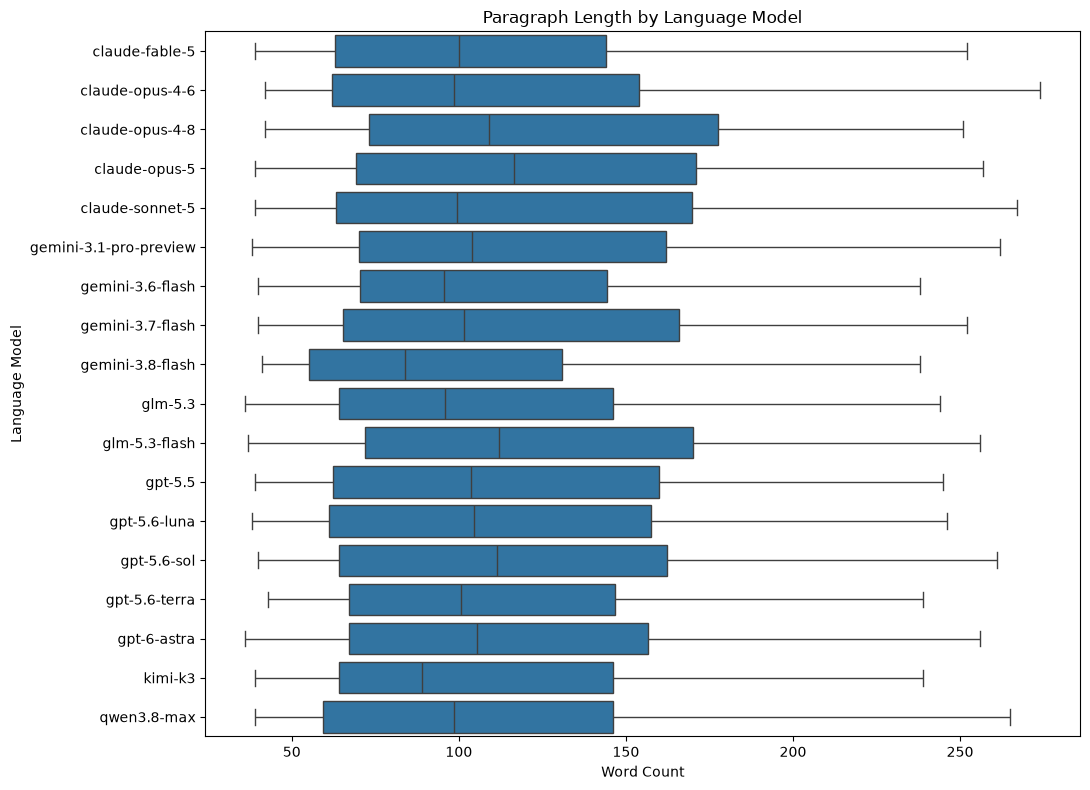

In [65]:
# Compare paragraph length distributions across models. Overlapping distributions may suggest that word count by itself may have limited model identification power.
exploration = data.copy()
exploration["word_count"] = (exploration["text"].str.split().str.len())

display(exploration.groupby("model")["word_count"].agg(["min", "median", "mean", "max"]).round(1))

plt.figure(figsize=(11, 8))

sns.boxplot(data=exploration,x="word_count",y="model",order=sorted(exploration["model"].unique()))
plt.title("Paragraph Length by Language Model")
plt.xlabel("Word Count")
plt.ylabel("Language Model")
plt.tight_layout()
plt.show()

In [66]:
# Count whitespace separated tokens in each paragraph. This is an approximate word count and becomes a candidate prediction feature.
data["word_count"] = (data["text"].str.split().str.len())

In [67]:
# Calculate average token length using English letter tokens. This measures vocabulary characteristics, but excludes numbers and non English letters.
def average_word_length(text):
    words = re.findall(r'\b[A-Za-z]+\b', str(text))
    return sum(len(word) for word in words) / len(words) if words else 0

data['avg_word_length'] = data['text'].fillna('').apply(average_word_length)

In [68]:
# Use NLTK to separate sentences, then calculate average whitespace separated words per sentence. Sentence boundary mistakes may affect this measurement.
def average_sentence_length(text):
    sentences = sent_tokenize(str(text))

    if not sentences:
        return 0

    word_count = sum(
        len(sentence.split())
        for sentence in sentences
    )

    return word_count / len(sentences)

data['avg_sentence_length'] = data['text'].fillna('').apply(
    average_sentence_length
)

In [69]:
# Count the sentences identified by NLTK. Together with word count, this describes how a paragraph is structured.
data['sentence_count'] = data['text'].fillna('').apply(
    lambda x: len(sent_tokenize(x))
)

In [70]:
# Count characters in Python's ASCII punctuation set. This excludes Unicode punctuation such as curly quotation marks and em dashes.
data['punctuation_count'] = data['text'].fillna('').apply(
    lambda x: sum(1 for char in str(x) if char in string.punctuation)
)

In [71]:
# Count Unicode symbols, including mathematical and currency symbols. Some characters also belong to the ASCII punctuation set, and these features can overlap.
def count_symbols(text):
    return sum(
        1 for char in str(text)
        if unicodedata.category(char)[0] == 'S'
    )

data['symbol_count'] = data['text'].fillna('').apply(count_symbols)

In [72]:
# Identify which ASCII punctuation characters occur in this dataset so we can explore their individual frequencies.

# Combine all text into one string
all_text = data['text'].fillna('').astype(str).str.cat(sep='')

# Keep only punctuation marks that appear at least once
punctuation_list = [
    p for p in string.punctuation
    if p in all_text
]

print("Punctuation found:", punctuation_list)
print("Number of punctuation types:", len(punctuation_list))

Punctuation found: ['!', '"', '$', "'", '(', ')', '*', '+', ',', '-', '.', '/', ':', ';', '<', '=', '>', '?', '[', '\\', ']', '^', '_', '{', '}']
Number of punctuation types: 25


In [73]:
# Calculate each punctuation character's share of total counted punctuation. Using a minimum denominator of one prevents division by zero.

punctuation_total = data["punctuation_count"].clip(lower=1)

for p in punctuation_list:
    count = (data["text"].fillna("").astype(str).str.count(re.escape(p)))

    data[f"ratio_{p}"] = count / punctuation_total

In [74]:
# Preview the original columns alongside the newly created numerical writing features.
data

,id,prompt_id,text,model,word_count,avg_word_length,avg_sentence_length,sentence_count,punctuation_count,symbol_count,...,ratio_=,ratio_>,ratio_?,ratio_[,ratio_\,ratio_],ratio_^,ratio__,ratio_{,ratio_}
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max,192,4.782383,24.000000,8,28,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5,65,6.611940,16.250000,4,11,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash,77,5.012987,19.250000,4,12,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra,220,6.576577,24.444444,9,45,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash,97,4.343434,24.250000,4,13,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2694,ff4344ceda23,p075,"Across centuries of silence and shadow, an inv...",gemini-3.8-flash,156,5.668790,26.000000,6,20,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2695,ff507658ba82,p092,Though both instruments breathe the exact same...,gemini-3.7-flash,74,6.094595,18.500000,4,12,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2696,ff50c252810c,p113,A single photon leaves the star as neither wav...,claude-opus-4-8,83,4.506024,20.750000,4,12,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2697,ffcf6321f7e9,p073,Data science communities matter because they t...,glm-5.3,83,6.929412,16.600000,5,17,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,word_count,avg_word_length,avg_sentence_length,sentence_count,punctuation_count,symbol_count,punctuation_per_100_words
count,2699.00,2699.00,2699.00,2699.00,2699.00,2699.00,2699.00
mean,114.66,5.39,24.03,4.86,17.76,0.03,16.08
std,58.28,0.53,10.35,2.17,8.87,0.27,4.13
min,36.00,3.84,9.20,1.00,1.00,0.00,1.04
25%,64.00,5.02,19.60,3.00,11.00,0.00,13.24
50%,101.00,5.35,22.80,5.00,16.00,0.00,15.50
75%,157.00,5.72,26.50,6.00,23.50,0.00,18.18
max,274.00,7.37,220.00,14.00,93.00,6.00,73.33


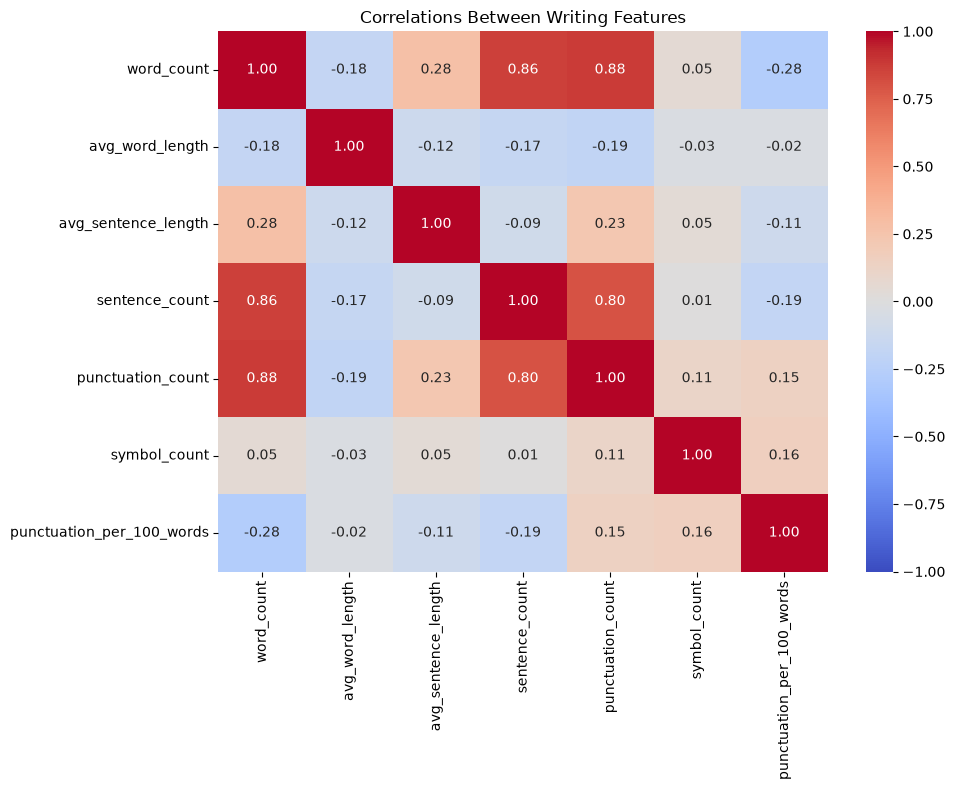

In [75]:
# Measure punctuation relative to paragraph length and look at correlations between numerical features. Correlation describes relationships, it does not establish prediction accuracy.

data["punctuation_per_100_words"] = (
    data["punctuation_count"]
    / data["word_count"].clip(lower=1)
    * 100
)

feature_columns = [
    "word_count",
    "avg_word_length",
    "avg_sentence_length",
    "sentence_count",
    "punctuation_count",
    "symbol_count",
    "punctuation_per_100_words"
]

display(data[feature_columns].describe().round(2))

correlations = data[feature_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlations,annot=True,fmt=".2f",cmap="coolwarm",center=0,vmin=-1,vmax=1)
plt.title("Correlations Between Writing Features")
plt.tight_layout()
plt.show()

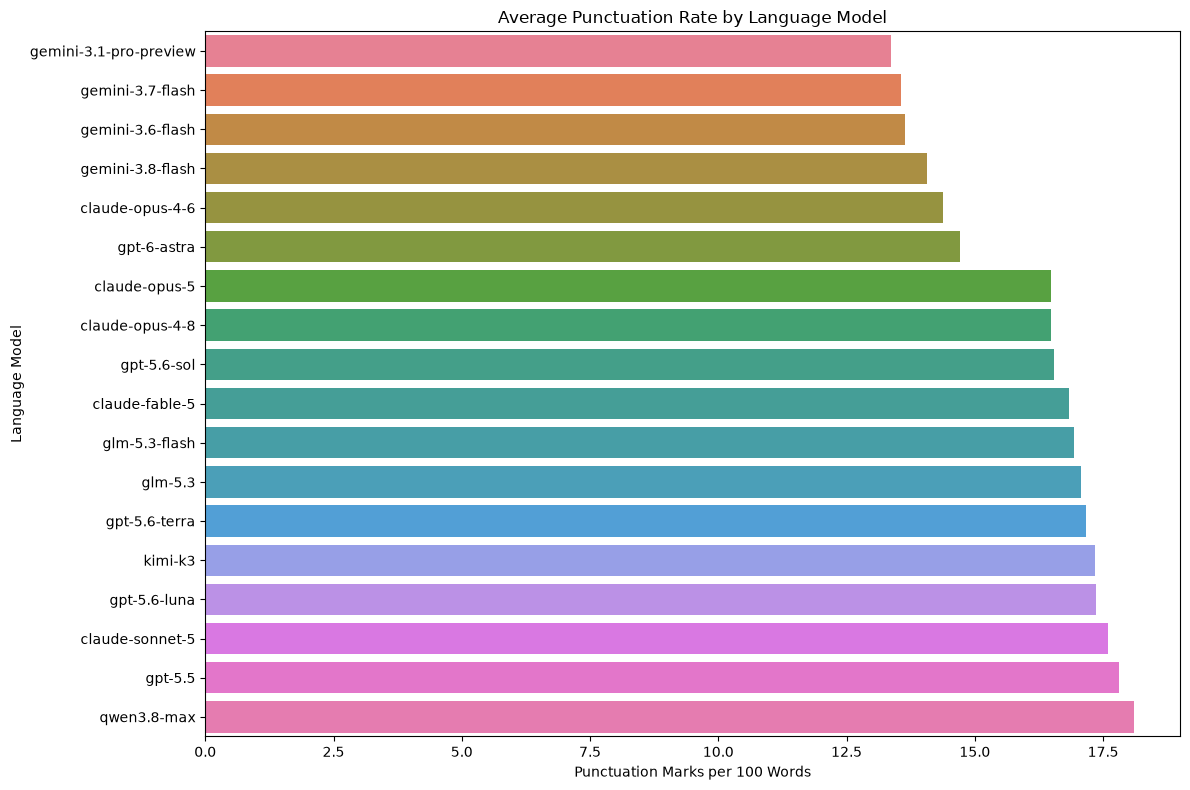

In [76]:
model_stats = (
    data.groupby("model")["punctuation_per_100_words"]
    .mean()
    .sort_values()
    .reset_index()
)

# Create horizontal bar chart
plt.figure(figsize=(12, 8))

sns.barplot(
    data=model_stats,
    x="punctuation_per_100_words",
    y="model",
    hue="model",
    palette="husl",
    legend=False
)

plt.title("Average Punctuation Rate by Language Model")
plt.xlabel("Punctuation Marks per 100 Words")
plt.ylabel("Language Model")
plt.tight_layout()
plt.show()

# Based on the graph, the models appear to form two potential clusters. 
# Further analysis is needed to determine whether these groups are statistically distinct.

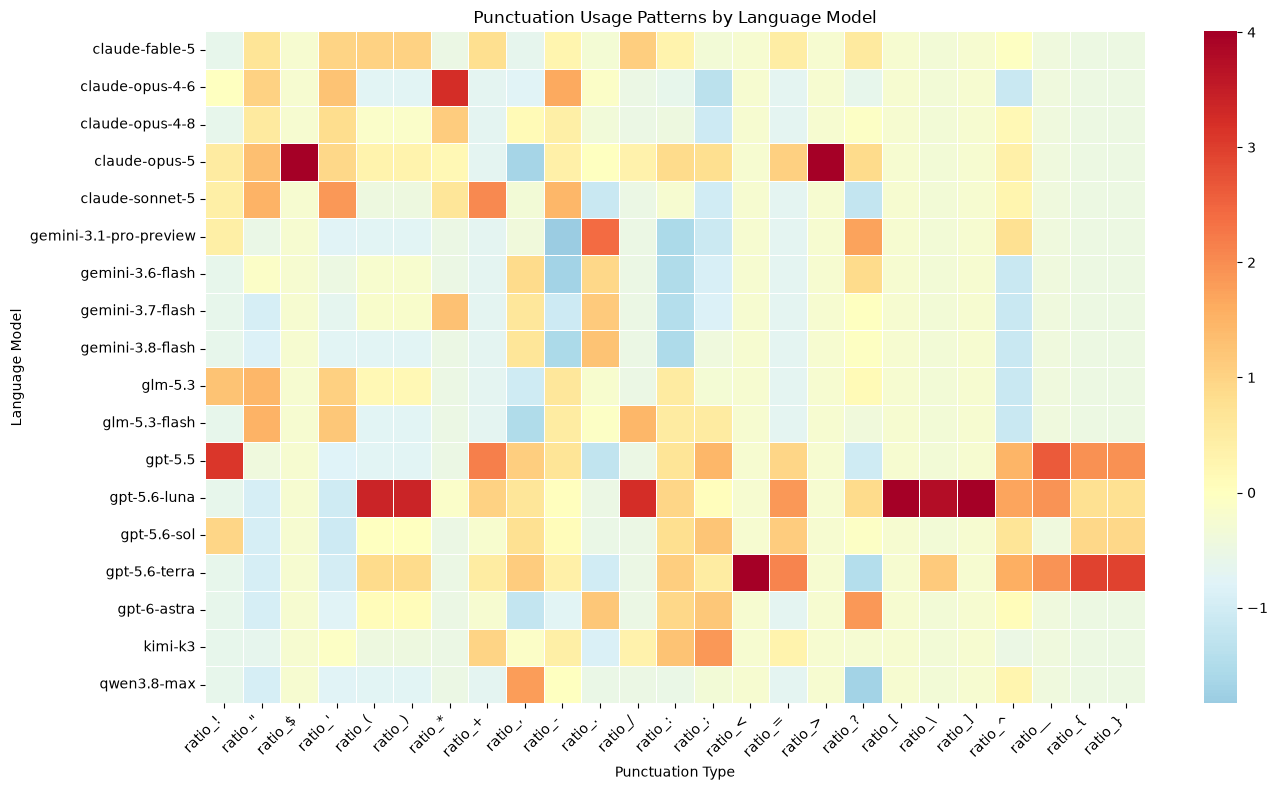

In [77]:
ratio_cols = [
    col for col in data.columns
    if col.startswith("ratio_")
]

# Calculate average punctuation ratios per model
model_stats = data.groupby("model")[ratio_cols].mean()

# Standardize each punctuation feature to compare patterns
heatmap_data = (
    model_stats - model_stats.mean()
) / model_stats.std().replace(0, 1)

# Generate heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data,
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.5,
    annot=False
)

plt.title("Punctuation Usage Patterns by Language Model")
plt.xlabel("Punctuation Type")
plt.ylabel("Language Model")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# The heatmap reveals punctuation patterns across language models. Some models appear to favor specific punctuation marks more than others. 
# For example, GPT-5.6-Luna exhibits relatively high usage of: "(", ")", "/", "[", "]", "\".
# The opposite is also true. Models from the Gemini family tends to not use ":".
# These differences suggest that punctuation usage may be useful to differenciate language models.

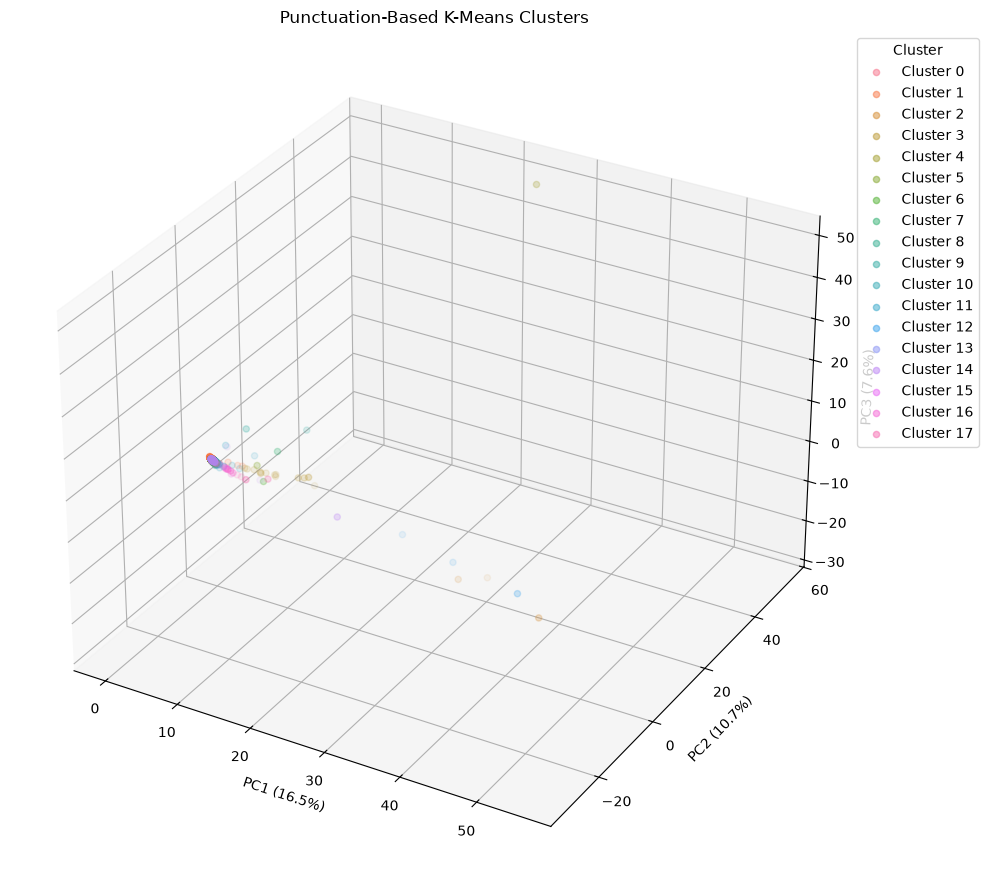

Variance explained by 3 PCs: 34.8%


In [78]:
ratio_cols = [
    col for col in data.columns
    if col.startswith("ratio_")
]

df_cluster = data[ratio_cols + ["model"]].copy()
X = df_cluster[ratio_cols]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Assume one cluter per model
n_clusters = df_cluster["model"].nunique()

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=6600,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)

# Reduce features to three principal components
pca = PCA(n_components=3)
X_3d = pca.fit_transform(X_scaled)

# Visualize clusters
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

colors = sns.color_palette("husl", n_clusters)

for cluster in range(n_clusters):
    mask = labels == cluster

    ax.scatter(
        X_3d[mask, 0],
        X_3d[mask, 1],
        X_3d[mask, 2],
        color=colors[cluster],
        alpha=0.5,
        s=20,
        label=f"Cluster {cluster}"
    )

variance = pca.explained_variance_ratio_ * 100

ax.set_xlabel(f"PC1 ({variance[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({variance[1]:.1f}%)")
ax.set_zlabel(f"PC3 ({variance[2]:.1f}%)")

ax.set_title("Punctuation-Based K-Means Clusters")
ax.legend(title="Cluster", bbox_to_anchor=(1.15, 1))

plt.tight_layout()
plt.show()

print(f"Variance explained by 3 PCs: {variance.sum():.1f}%")

# Three PCs explains 34.8% of the variance. This might be a little light.

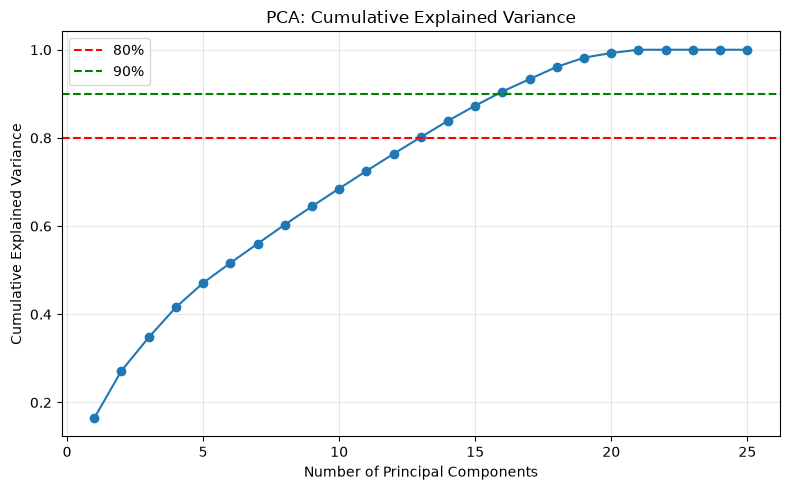

In [79]:
pca_full = PCA().fit(X_scaled)

cumulative_variance = pca_full.explained_variance_ratio_.cumsum()

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(0.80, color="red", linestyle="--", label="80%")
plt.axhline(0.90, color="green", linestyle="--", label="90%")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# We would need a minimum of 14 PCs to explain over 80% of the variance. 
# Punctuation is complex and required a relatively high number of PCs to explain variance. 

In [80]:
# Flag unusual sentence lengths and punctuation rates using the 1.5 * IQR rule. Inspect examples to distinguish legitimate writing patterns from measurement or data errors.
features_to_review = ["avg_sentence_length","punctuation_per_100_words"]

for feature in features_to_review:
    # Calculate the range containing the middle half of the values.
    q1 = data[feature].quantile(0.25)
    q3 = data[feature].quantile(0.75)
    iqr = q3 - q1

    # 1.5 * IQR rule to flag any outliers.
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    flagged = data.loc[(data[feature] < lower_limit)| (data[feature] > upper_limit)]

    print(f"\nFeature: {feature}")
    print(f"Review limits: {lower_limit:.2f} to {upper_limit:.2f}")
    print(f"Number of flagged paragraphs: {len(flagged)}")

    display(flagged[["id", "model", feature]])

    # Read the paragraph with the largest value to understand the flag.
    if not flagged.empty:
        largest_index = flagged[feature].idxmax()

        print("Paragraph with the largest flagged value:")
        print(data.loc[largest_index, "text"])


Feature: avg_sentence_length
Review limits: 9.25 to 36.85
Number of flagged paragraphs: 91


,id,model,avg_sentence_length
7,010b4f492abc,claude-opus-4-6,38.5
15,018b5e011a51,claude-opus-4-6,50.0
30,0324d70bc185,claude-sonnet-5,41.0
37,0408e914e870,kimi-k3,41.0
49,050837aef9a3,claude-fable-5,51.0
...,...,...,...
2446,eabb7436c119,gpt-5.6-sol,49.0
2475,ecbdee773f9c,glm-5.3,42.0
2487,ee1d6ad0ec5f,claude-opus-4-6,38.5
2497,ef69f5a64ab3,gpt-5.6-terra,45.2


Paragraph with the largest flagged value:
Cold light piercing the blinds, blue-white striping the duvet where my toes kick out numb, static buzzing in the radiator, wait, did I leave the kettle on, no, that was yesterday or in the dream with the red umbrella floating past the office window three stories up where the printer jammed again, red light flashing paper jam feed tray two, god, my neck is stiff like dried glue on cardboard, turning slowly to the tick-tick-ticking of the wall clock counting down to seven thirty, no, seven thirty-four already, late, the train won't wait for anyone, especially not me with one shoe missing somewhere under the dust bunnies behind the wardrobe where old letters smell like dried lavender and damp cellar dirt, breathe in through the nose, out through the mouth like that meditation video said, but my ribs feel tight, wrapped in copper wire, hum of the refrigerator kicking on, low vibration through the floorboards into my heels, is it raining outside, th

,id,model,punctuation_per_100_words
77,079b7e92792c,glm-5.3-flash,26.785714
84,07f409f75b21,gpt-5.6-luna,29.411765
182,1275d7931666,claude-sonnet-5,28.125000
214,16364cb47b35,claude-opus-5,27.272727
222,16b9932865c9,gpt-5.5,31.818182
...,...,...,...
2527,f1e87992700f,claude-opus-4-6,27.272727
2557,f3f0e5d9b09d,claude-fable-5,26.086957
2600,f89858c58633,qwen3.8-max,26.785714
2638,fb07ed3f0ede,claude-sonnet-5,27.272727


Paragraph with the largest flagged value:
Let \(T\) be a consistent formal theory, and let \(T^+\) extend \(T\) with a truth predicate or stronger induction. A theorem \(\varphi\) may require millions of symbols in \(T\), yet admit a one-line proof in \(T^+\): “By the certified induction principle, \(\varphi\).” This is Gödelian speedup: leaving the original framework does not shorten reasoning; it makes previously inaccessible justification available.


### Observations:

